In [1]:
import numpy as np 
import pandas as pd
import scanpy as sc 
import matplotlib.pyplot as plt
import os 
# save_dir = 'supp_species/analysis'
# os.makedirs(save_dir, exist_ok = True)
from sklearn.preprocessing import minmax_scale

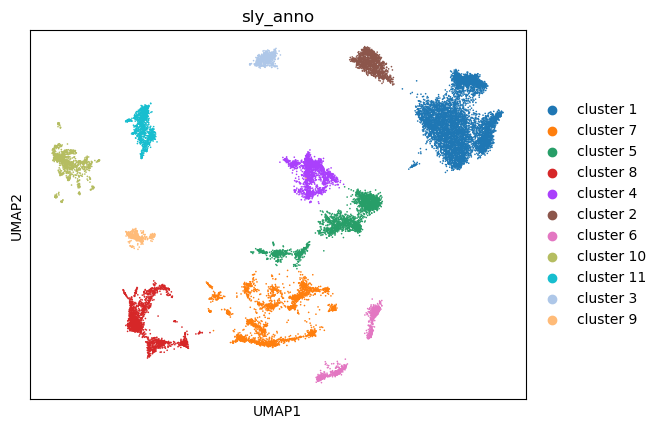

In [2]:
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad') 
sc.pl.umap(scdata, color = 'sly_anno')

In [5]:
df = pd.crosstab(scdata.obs.species, scdata.obs.sly_anno)
df[df.values <= 15] = 0
df.to_csv('counts_multi.csv')

## Five species

In [2]:
mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

## re-normalize 
scdata = mdata.copy()
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)


idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'Synpr'].X.toarray()
u = np.percentile(x, 25)

(21723, 9911) (21723, 9911)


### CY

In [ ]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'CY'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'



## PLOT CODE ##



In [ ]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'JT'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

## PLOT CODE ##

In [ ]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'T'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

## PLOT CODE ##

In [ ]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'QF'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'


## PLOT CODE ##

In [ ]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'M'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

## PLOT CODE ##


## Dog

In [ ]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/dog_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

## load query data
# adata = sc.read_h5ad('supp_species/dog_ex_neu.h5ad')
species = 'dog'



(21723, 9911) (21723, 9911)
mutual gene number 8819


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.226362109184265


In [ ]:
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'


## PLOT CODE ##

## Human

In [ ]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/human_ex_neu_filter.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

In [ ]:
species = 'human'
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'



## PLOT CODE ##

## Rhesus Macaque

In [13]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/mihou_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

(21723, 9911) (21723, 9911)
mutual gene number 8394


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.249342679977417


In [ ]:
species = 'monkey'
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'


## PLOT CODE ##

## Axolotl

In [15]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/dunkouyuan_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

(21723, 9911) (21723, 9911)
mutual gene number 8465


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.2419021129608154


In [ ]:
species = 'dunkouyuan'
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'


## PLOT CODE ##

## Chinese tree shrew

In [11]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/shuqu_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

(21723, 9911) (21723, 9911)
mutual gene number 8259


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.2653262615203857


In [19]:
sample_list = []
for ele in adata.obs.index:
    sample_list.append(ele.split('|')[0])
adata.obs.loc[:,'sample_id'] = sample_list 
adata.obs.sample_id.value_counts()
adata = adata[adata.obs.sample_id == 'TS1']

In [ ]:
species = 'shuqu'
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

## PLOT CODE ##

## Corn Snake

In [19]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/snake_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')


# ## query new pca 
# sc.pp.h

(21723, 9911) (21723, 9911)
mutual gene number 8450


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.2415720224380493


In [ ]:
species = 'snake'
adata = sc.read_h5ad('../supp_species/snake_ex_neu.h5ad')
species = 'snake'
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=3000)
adata = adata[:,adata.var.highly_variable]

sc.tl.pca(adata)
sc.pp.neighbors(adata)

sc.tl.umap(adata, min_dist = 0.5)
sc.tl.leiden(adata, resolution = 0.1)
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata.raw[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata.raw[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata.raw[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata.raw[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata.raw[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata.raw[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata.raw[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

## PLOT CODE ##

## zebrafish

In [ ]:
scdata = sc.read_h5ad('../supp_species/banmayu_ex_neu.h5ad') 

adata = scdata.copy()
species = 'banmayu'
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=3000)
adata = adata[:,adata.var.highly_variable]
sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata, min_dist = 0.5)

In [ ]:
idx_1 = adata.raw[:,'SYNPR'].X.toarray() >= 2
idx_2 = adata.raw[:,'OTOF'].X.toarray() > 0 
# idx_3 = adata.raw[:,'CSMD1'].X.toarray() == 0
idx_4 = adata.raw[:,'PEX5L'].X.toarray() == 0 
idx_c1 = ((idx_1 | idx_2)  & idx_4).ravel() #& idx_3

# idx_1 = adata.raw[:,'CSMD1'].X.toarray() > 0 
idx_2 = adata.raw[:,'SOX5'].X.toarray() == 0
idx_3 = adata.raw[:,'SYNPR'].X.toarray() > 0 
idx_c2 = (idx_2 & idx_3).ravel() #idx_1 & idx_2 & idx_3 


# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

## PLOT CODE ##